In [10]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone

<Axes: >

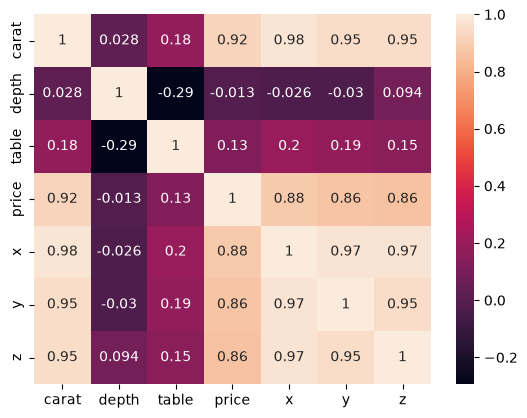

In [8]:



df = pd.read_csv('./archive/diamonds.csv')
df.head()
df.describe().T
df.isna().sum()
numeric = df.select_dtypes(include='number').columns
corr = df[numeric].corr()

sns.heatmap(data=corr, annot=True)


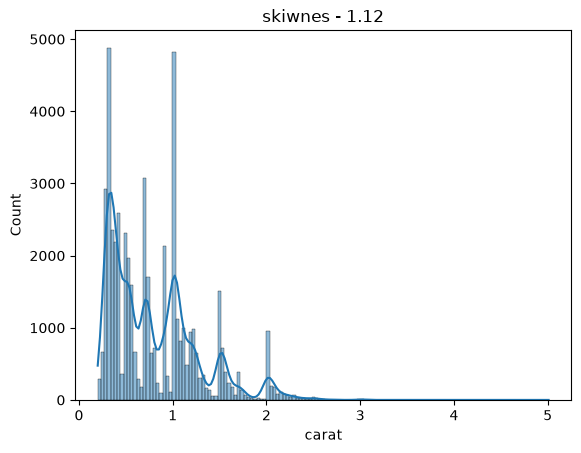

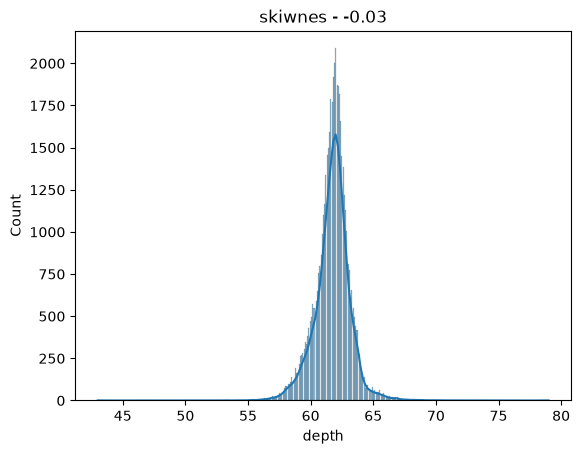

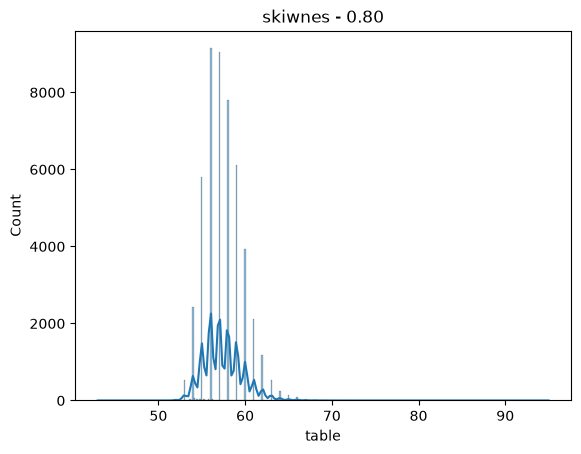

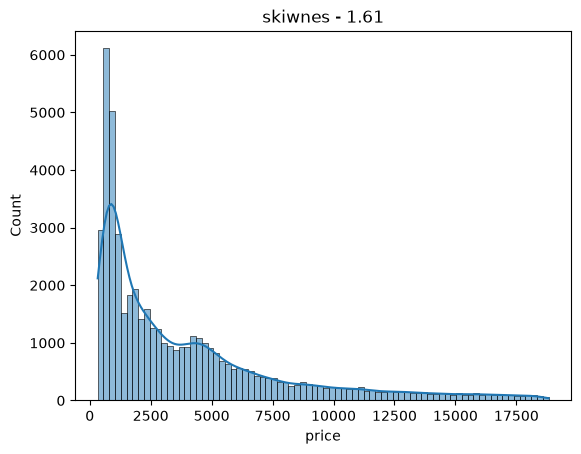

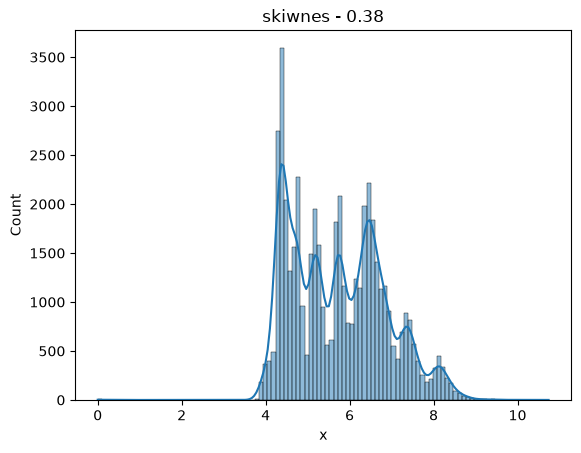

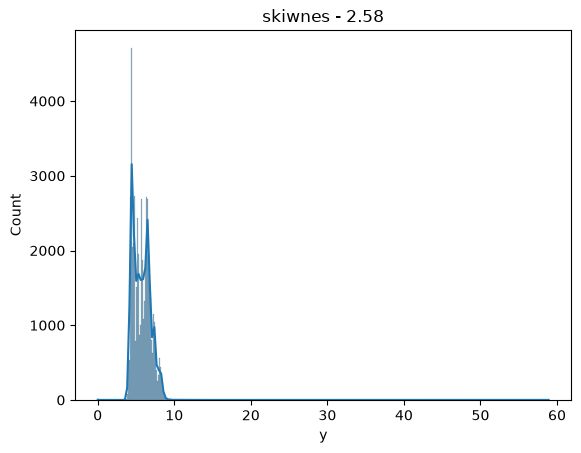

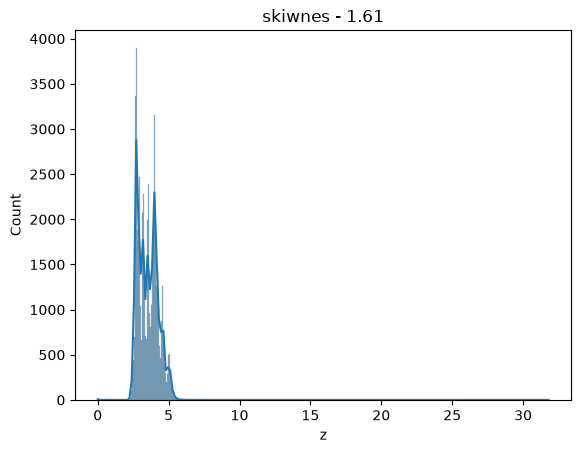

In [11]:
for col in numeric:
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"skiwnes - {df[col].skew():.2f}")
    plt.show()

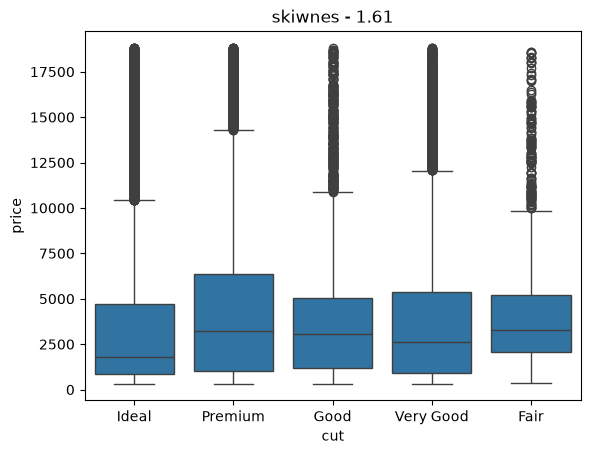

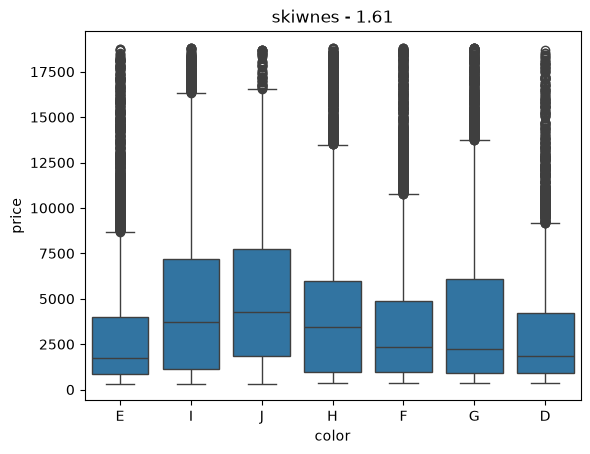

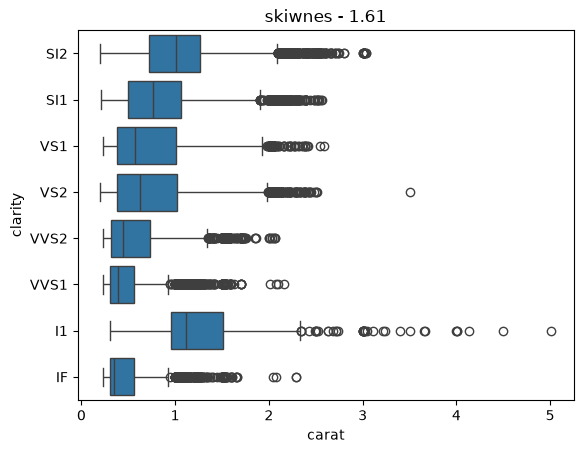

In [12]:
sns.boxplot(data=df, x='cut', y='price')
plt.title(f"skiwnes - {df[col].skew():.2f}")
plt.show()

sns.boxplot(data=df, x='color', y='price')
plt.title(f"skiwnes - {df[col].skew():.2f}")
plt.show()

sns.boxplot(data=df, x='carat', y='clarity')
plt.title(f"skiwnes - {df[col].skew():.2f}")
plt.show()

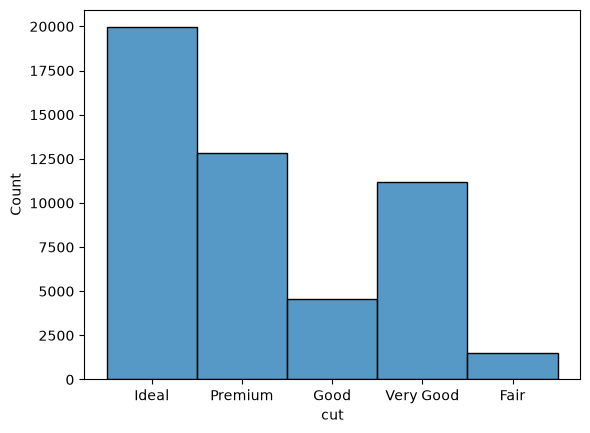

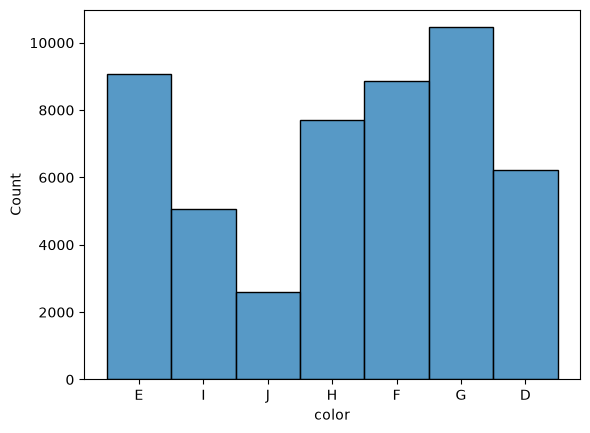

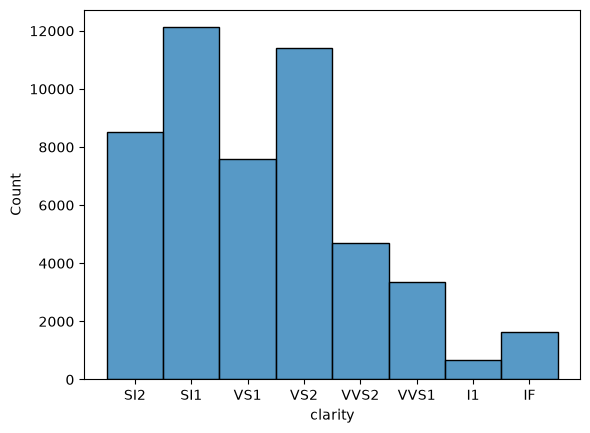

In [14]:
df.groupby('cut').count()
sns.histplot(data=df, x='cut')
plt.show()

sns.histplot(data=df, x='color')
plt.show()

sns.histplot(data=df, x='clarity')
plt.show()

In [18]:
pd.Series(False, index=df.index)

0        False
1        False
2        False
3        False
4        False
         ...  
49995    False
49996    False
49997    False
49998    False
49999    False
Length: 50000, dtype: bool

In [28]:
def get_outliers(df:pd.DataFrame, cols: list):
    result = []
    mask = pd.Series(False, index=df.index)

    for col in cols:
        IQ1, IQ3 = df[col].quantile([0.25, 0.75])
        IQR = IQ3 - IQ1
        MIN_VAL = IQ1 - 1.5 * IQR 
        MAX_VAL = IQ3 + 1.5 * IQR
        
        col_mask = (df[col] < MIN_VAL) | (df[col] > MAX_VAL)
        mask |= col_mask
        outliers = df[col_mask][col]
        outliers_len = len(outliers)

        result.append({
            'column' : col,
            'lower_bound' : MIN_VAL,
            'max_bound' : MAX_VAL,
            'outliers_count' : outliers_len,
            'outliers_percentage' : outliers_len / len(df) * 100,
        })
    return df.loc[mask], mask, pd.DataFrame(result)

outliers , mask, result = get_outliers(df, numeric)
result

,column,lower_bound,max_bound,outliers_count,outliers_percentage
0,carat,-0.560,2.000,1752,3.514050
1,depth,58.750,64.750,2339,4.691417
2,table,51.500,63.500,556,1.115189
3,price,-5646.500,11949.500,3250,6.518643
4,x,1.990,9.270,24,0.048138
5,y,1.990,9.270,22,0.044126
6,z,1.215,5.735,26,0.052149


In [29]:
mask.mean() * 100

np.float64(11.839862005335258)

Preprocessing

In [23]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)
df.reset_index(inplace=True, drop=True)
df.duplicated().sum()


np.int64(0)

In [24]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [27]:

zero_mask = (df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)
df = df[~zero_mask]


In [31]:
X, Y = df.drop(columns=['price']), df['price']
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, shuffle=True, random_state=42)

models = {
    'LinearRegression' : LinearRegression(),
    'RandomForestRegressor' : RandomForestRegressor()
}

models_param = {
    'LinearRegression' : {
            'regressor__positive': [True, False],
            'regressor__fit_intercept': [True, False],
        },
    'RandomForestRegressor' : {
        "regressor__n_estimators" : [100, 200, 300],
        "regressor__max_depth" : [10, 20, 50, None],
        "regressor__min_samples_split" : [2, 5, 10],
    }
}

numeric_features = ['carat', 'depth', "table", "x", "y", "z"]
ordinal_features = ['cut', 'color', 'clarity']
nominal_features = []

cut_order = ['Fair', "Good", 'Very Good', 'Premium', "Ideal"]
color_order = ["J", "I", 'H', "G", 'F', 'E', "D"]
clarity_order = ["I1", "SI2", 'SI1', "VS2", 'VS1', 'VVS2', "VVS1", 'IF']

preprocessor = ColumnTransformer([
    ('numeric_scaler', StandardScaler(), numeric_features),
    ('ordinal_encoder', OrdinalEncoder(categories=[cut_order, color_order, clarity_order]), ordinal_features ),
    ('nominal_encoder', OneHotEncoder(), nominal_features),
])

def make_pipline(model, preprocessor):
    return Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])


result = []

for name, model in models.items():
    contestant = GridSearchCV(
        make_pipline(model, preprocessor),
        param_grid=models_param[name],
        cv=3,
        n_jobs=-1
    )
    contestant.fit(x_train, y_train)
    best_model = contestant.best_estimator_
    best_params = contestant.best_params_
    predict = contestant.predict(x_test)
    
    result.append({
        "model": best_model,
        "name": name,
        "RMSE": -contestant.best_score_,
        "MSE": mean_squared_error(y_test, predict),
        "RMSE": np.sqrt(mean_squared_error(y_test, predict)),
        "MAE": mean_absolute_error(y_test, predict),
        "R2": r2_score(y_test, predict),
        "best_params": best_params
    })
result = pd.DataFrame(result)

/home/mohamed/Documents/Github/Gho-byte/Plan_d_action/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [32]:
result
best_result = result.loc[result['RMSE'].idxmin(), ['model']]

In [33]:
joblib.dump(best_result, 'best_result.pkl')

['best_result.pkl']